In [105]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore') 
df = pd.read_csv("nyc-rolling-sales.csv")
# df 

In [ ]:
# What type of ML problem is this => Regression
# Why => Because the target is continuous.
# Target variable => SALE PRICE 

In [106]:
df.shape
df.describe() 
df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84548 entries, 0 to 84547
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Unnamed: 0                      84548 non-null  int64 
 1   BOROUGH                         84548 non-null  int64 
 2   NEIGHBORHOOD                    84548 non-null  object
 3   BUILDING CLASS CATEGORY         84548 non-null  object
 4   TAX CLASS AT PRESENT            84548 non-null  object
 5   BLOCK                           84548 non-null  int64 
 6   LOT                             84548 non-null  int64 
 7   EASE-MENT                       84548 non-null  object
 8   BUILDING CLASS AT PRESENT       84548 non-null  object
 9   ADDRESS                         84548 non-null  object
 10  APARTMENT NUMBER                84548 non-null  object
 11  ZIP CODE                        84548 non-null  int64 
 12  RESIDENTIAL UNITS               84548 non-null

Index(['Unnamed: 0', 'BOROUGH', 'NEIGHBORHOOD', 'BUILDING CLASS CATEGORY',
       'TAX CLASS AT PRESENT', 'BLOCK', 'LOT', 'EASE-MENT',
       'BUILDING CLASS AT PRESENT', 'ADDRESS', 'APARTMENT NUMBER', 'ZIP CODE',
       'RESIDENTIAL UNITS', 'COMMERCIAL UNITS', 'TOTAL UNITS',
       'LAND SQUARE FEET', 'GROSS SQUARE FEET', 'YEAR BUILT',
       'TAX CLASS AT TIME OF SALE', 'BUILDING CLASS AT TIME OF SALE',
       'SALE PRICE', 'SALE DATE'],
      dtype='object')

In [107]:
df.duplicated().sum()
df.nunique()
df.describe(include='object') 
df.dtypes

Unnamed: 0                         int64
BOROUGH                            int64
NEIGHBORHOOD                      object
BUILDING CLASS CATEGORY           object
TAX CLASS AT PRESENT              object
BLOCK                              int64
LOT                                int64
EASE-MENT                         object
BUILDING CLASS AT PRESENT         object
ADDRESS                           object
APARTMENT NUMBER                  object
ZIP CODE                           int64
RESIDENTIAL UNITS                  int64
COMMERCIAL UNITS                   int64
TOTAL UNITS                        int64
LAND SQUARE FEET                  object
GROSS SQUARE FEET                 object
YEAR BUILT                         int64
TAX CLASS AT TIME OF SALE          int64
BUILDING CLASS AT TIME OF SALE    object
SALE PRICE                        object
SALE DATE                         object
dtype: object

In [108]:
df.isnull().sum()
print((df['LAND SQUARE FEET'] == '- ').sum())
print((df['GROSS SQUARE FEET'] == '- ').sum())
print((df['SALE PRICE'] == '- ').sum())

df.replace(r'^\s*-\s*$', np.nan, regex=True, inplace=True)
df.isnull().sum() 

df.isnull().sum()
df.head(5)

0
0
0


,Unnamed: 0,BOROUGH,NEIGHBORHOOD,BUILDING CLASS CATEGORY,TAX CLASS AT PRESENT,BLOCK,LOT,EASE-MENT,BUILDING CLASS AT PRESENT,ADDRESS,...,RESIDENTIAL UNITS,COMMERCIAL UNITS,TOTAL UNITS,LAND SQUARE FEET,GROSS SQUARE FEET,YEAR BUILT,TAX CLASS AT TIME OF SALE,BUILDING CLASS AT TIME OF SALE,SALE PRICE,SALE DATE
0,4,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2A,392,6,,C2,153 AVENUE B,...,5,0,5,1633,6440,1900,2,C2,6625000,2017-07-19 00:00:00
1,5,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,399,26,,C7,234 EAST 4TH STREET,...,28,3,31,4616,18690,1900,2,C7,NaN,2016-12-14 00:00:00
2,6,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,399,39,,C7,197 EAST 3RD STREET,...,16,1,17,2212,7803,1900,2,C7,NaN,2016-12-09 00:00:00
3,7,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,402,21,,C4,154 EAST 7TH STREET,...,10,0,10,2272,6794,1913,2,C4,3936272,2016-09-23 00:00:00
4,8,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2A,404,55,,C2,301 EAST 10TH STREET,...,6,0,6,2369,4615,1900,2,C2,8000000,2016-11-17 00:00:00


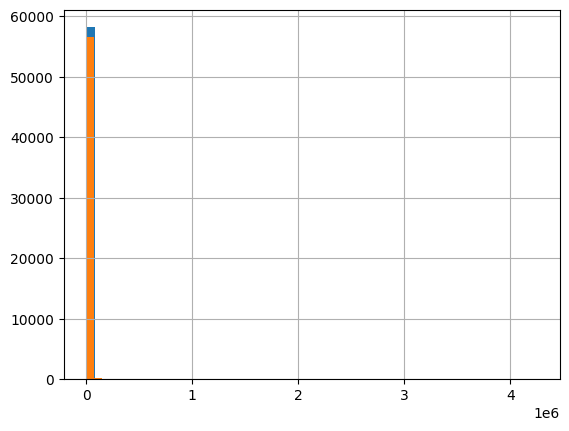

In [109]:

df['LAND SQUARE FEET'] = pd.to_numeric(
    df['LAND SQUARE FEET'],
    errors='coerce'
)

df['GROSS SQUARE FEET'] = pd.to_numeric(
    df['GROSS SQUARE FEET'],
    errors='coerce'
)
# Almost all the observations are clustered near 0, while a few values extend far to the right (up to around 4 million).
# This is called a Right-Skewed (Positively Skewed) distribution.

df['LAND SQUARE FEET'].hist(bins=50)
df['GROSS SQUARE FEET'].hist(bins=50)

df['LAND SQUARE FEET'].skew()
df['GROSS SQUARE FEET'].skew()

df['LAND SQUARE FEET'] = df['LAND SQUARE FEET'].fillna(
    df['LAND SQUARE FEET'].median()
)

df['GROSS SQUARE FEET'] = df['GROSS SQUARE FEET'].fillna(
    df['GROSS SQUARE FEET'].median()
)
# df['SALE PRICE'].hist(bins=50)
# df['SALE PRICE'].skew()

In [110]:
df = df.dropna(subset=['SALE PRICE'])
df.head()

,Unnamed: 0,BOROUGH,NEIGHBORHOOD,BUILDING CLASS CATEGORY,TAX CLASS AT PRESENT,BLOCK,LOT,EASE-MENT,BUILDING CLASS AT PRESENT,ADDRESS,...,RESIDENTIAL UNITS,COMMERCIAL UNITS,TOTAL UNITS,LAND SQUARE FEET,GROSS SQUARE FEET,YEAR BUILT,TAX CLASS AT TIME OF SALE,BUILDING CLASS AT TIME OF SALE,SALE PRICE,SALE DATE
0,4,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2A,392,6,,C2,153 AVENUE B,...,5,0,5,1633.0,6440.0,1900,2,C2,6625000,2017-07-19 00:00:00
3,7,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,402,21,,C4,154 EAST 7TH STREET,...,10,0,10,2272.0,6794.0,1913,2,C4,3936272,2016-09-23 00:00:00
4,8,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2A,404,55,,C2,301 EAST 10TH STREET,...,6,0,6,2369.0,4615.0,1900,2,C2,8000000,2016-11-17 00:00:00
6,10,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,406,32,,C4,210 AVENUE B,...,8,0,8,1750.0,4226.0,1920,2,C4,3192840,2016-09-23 00:00:00
9,13,1,ALPHABET CITY,08 RENTALS - ELEVATOR APARTMENTS,2,387,153,,D9,629 EAST 5TH STREET,...,24,0,24,4489.0,18523.0,1920,2,D9,16232000,2016-11-07 00:00:00


# Univariate Analysis

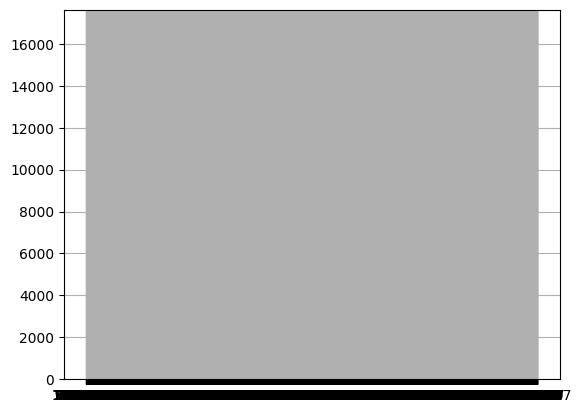

TypeError: ufunc 'divide' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

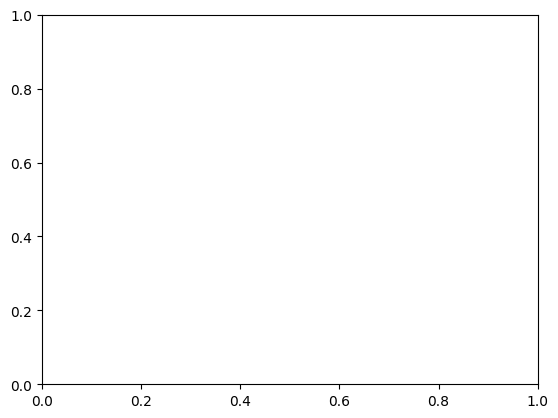

In [111]:
import matplotlib.pyplot as plt

df['SALE PRICE'].hist(bins=50)
plt.show() 

plt.boxplot(df['SALE PRICE'])
plt.show()  

df['SALE PRICE'].describe()
df['BOROUGH'].value_counts()
df['BOROUGH'].value_counts().plot(kind='bar') 
df['BOROUGH'].value_counts().plot(kind='pie')  

# Bivariate Analysis

In [ ]:
plt.scatter(df['GROSS SQUARE FEET'],
            df['SALE PRICE'])
plt.xlabel("Gross Square Feet")
plt.ylabel("Sale Price")
plt.show()   

# plt.scatter(df['LAND SQUARE FEET'],
#             df['SALE PRICE'])
# df.groupby('BOROUGH')['SALE PRICE'].mean()
# df.groupby('BOROUGH')['SALE PRICE'].mean().plot(kind='bar') 

# Multivariate Analysis

In [ ]:
df.corr(numeric_only=True)

plt.figure(figsize=(12,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

sns.pairplot(
    df[
        [
            'SALE PRICE',
            'LAND SQUARE FEET',
            'GROSS SQUARE FEET',
            'YEAR BUILT'
        ]
    ],
    diag_kind="kde"
)
plt.show()   

# Outlier Detection

In [ ]:
plt.boxplot(df['SALE PRICE'])  

# Feature Engineering

In [ ]:
df['HOUSE_AGE'] = 2025 - df['YEAR BUILT']
# df['SALE_YEAR'] = df['SALE DATE'].dt.year 
# df['SALE_MONTH'] = df['SALE DATE'].dt.month
df['PRICE_PER_SQFT'] = (
    df['SALE PRICE']
    / df['GROSS SQUARE FEET']
) 
df 

# Encoding

In [ ]:
X = pd.get_dummies(X,
                   drop_first=True)

# Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
) 

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)